In [ ]:
from google.colab import files

uploaded = files.upload()

Saving house_prices_practice.csv to house_prices_practice.csv


In [ ]:
import pandas as pd

df = pd.read_csv("house_prices_practice.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (300, 10)

Columns:
['Id', 'OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'YearBuilt', 'FullBath', 'BedroomAbvGr', 'LotArea', 'SalePrice']

First 5 rows:
   Id  OverallQual  GrLivArea  GarageCars  TotalBsmtSF  YearBuilt  FullBath  \
0   1            7       1560           0         1658       1969         2   
1   2            4       2827           2         1319       2012         3   
2   3            8       3920           0          841       2010         1   
3   4            5       3044           0         1058       1998         0   
4   5            7        801           1         2428       2020         0   

   BedroomAbvGr  LotArea  SalePrice  
0             1     8059     177106  
1             4    13530     301044  
2             4     9010     360609  
3             4    13207     240556  
4             1     9117     193656  

Missing Values:
Id              0
OverallQual     0
GrLivArea       0
GarageCars      0
TotalBsmtSF     0
YearBuilt  

EDA

In [ ]:
print(df.describe())
print(df.info())

               Id  OverallQual    GrLivArea  GarageCars  TotalBsmtSF  \
count  300.000000   300.000000   300.000000  300.000000   300.000000   
mean   150.500000     5.326667  2307.386667    1.330000  1468.796667   
std     86.746758     2.873001  1042.561303    1.109898   672.333705   
min      1.000000     1.000000   504.000000    0.000000   303.000000   
25%     75.750000     3.000000  1392.250000    0.000000   903.000000   
50%    150.500000     5.000000  2265.500000    1.000000  1502.000000   
75%    225.250000     8.000000  3306.500000    2.000000  2129.500000   
max    300.000000    10.000000  3998.000000    3.000000  2492.000000   

         YearBuilt    FullBath  BedroomAbvGr       LotArea      SalePrice  
count   300.000000  300.000000    300.000000    300.000000     300.000000  
mean   1986.163333    1.523333      2.926667   8969.453333  252262.903333  
std      21.377089    1.131543      1.456604   3753.531132   74998.055214  
min    1950.000000    0.000000      1.000000   

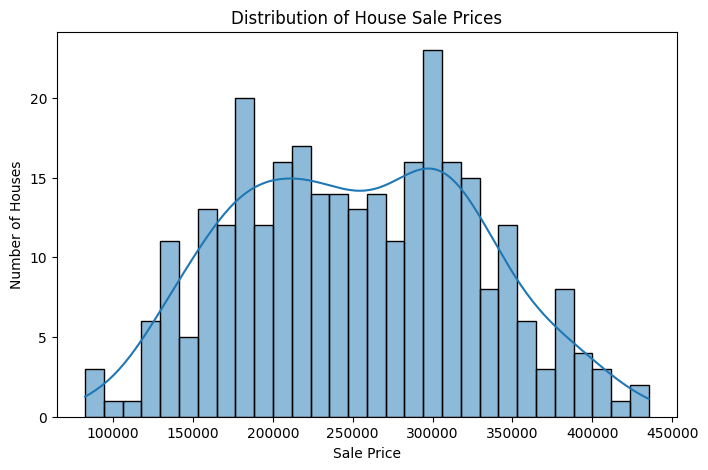

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(df["SalePrice"], bins=30, kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")

plt.show()

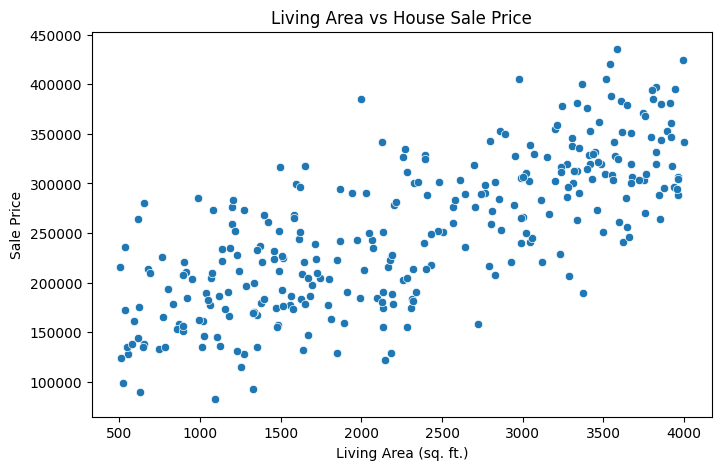

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="GrLivArea",
    y="SalePrice",
    data=df
)

plt.title("Living Area vs House Sale Price")
plt.xlabel("Living Area (sq. ft.)")
plt.ylabel("Sale Price")

plt.show()

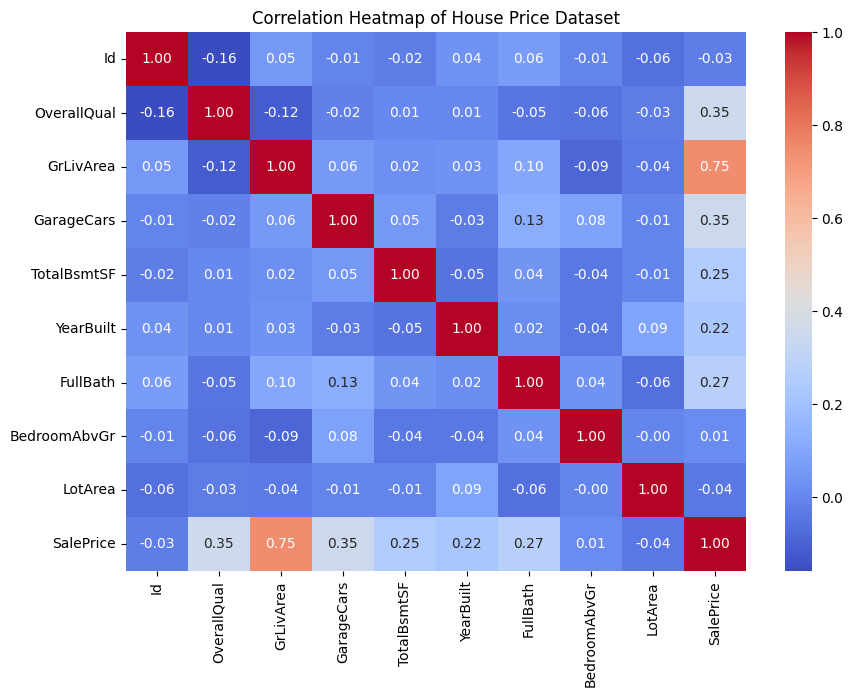

In [ ]:
plt.figure(figsize=(10, 7))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of House Price Dataset")

plt.show()

In [ ]:
# Remove Id because it is only an identifier
df_model = df.drop("Id", axis=1)

# Separate features and target
X = df_model.drop("SalePrice", axis=1)
y = df_model["SalePrice"]

print("Features:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'YearBuilt', 'FullBath', 'BedroomAbvGr', 'LotArea']

X shape: (300, 8)
y shape: (300,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training data:
X_train: (240, 8)
y_train: (240,)

Testing data:
X_test: (60, 8)
y_test: (60,)


In [ ]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [ ]:
y_pred_lr = lr_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred_lr[:10]
})

print(comparison)

   Actual Price  Predicted Price
0        224163    239161.363189
1        203881    190489.667985
2        380236    398000.957463
3        211664    223169.467552
4        122139    135188.395708
5        180067    180259.039807
6        275810    283708.271011
7        209025    204535.265477
8        213952    205837.941731
9        154885    171505.331960


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Performance:")
print("MAE :", mae_lr)
print("RMSE:", rmse_lr)
print("R²  :", r2_lr)

Linear Regression Performance:
MAE : 10431.655979707499
RMSE: 12505.459264619512
R²  : 0.9724369952260797


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [ ]:
y_pred_rf = rf_model.predict(X_test)

comparison_rf = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred_rf[:10]
})

print(comparison_rf)

   Actual Price  Predicted Price
0        224163        207318.36
1        203881        192735.91
2        380236        347509.91
3        211664        219556.22
4        122139        158336.51
5        180067        193689.47
6        275810        250121.10
7        209025        211329.43
8        213952        188491.50
9        154885        200377.37


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance:")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Performance:
MAE : 21414.515000000007
RMSE: 27405.669252765325
R²  : 0.8676243539162354


In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

        Feature  Importance
1     GrLivArea    0.637974
0   OverallQual    0.149002
2    GarageCars    0.064160
4     YearBuilt    0.052498
3   TotalBsmtSF    0.048517
5      FullBath    0.019071
7       LotArea    0.018819
6  BedroomAbvGr    0.009959


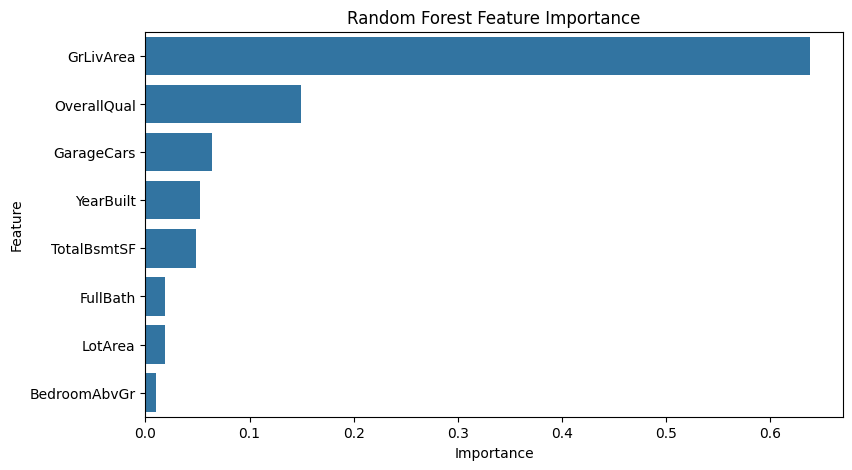

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

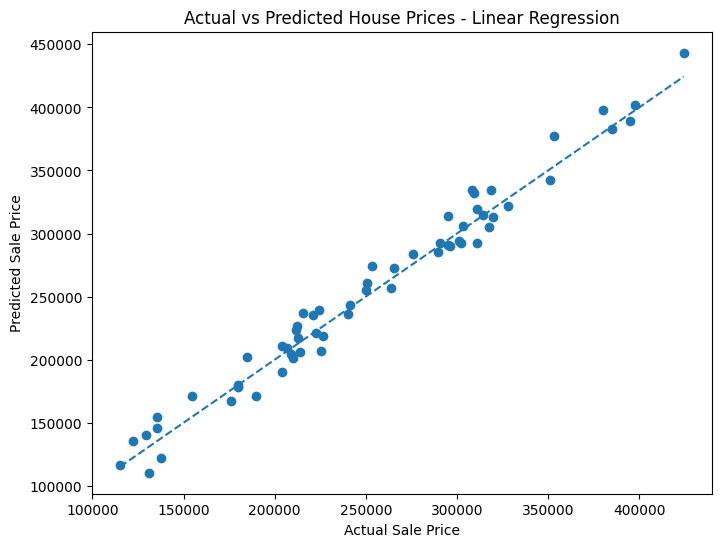

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_lr)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices - Linear Regression")

plt.show()

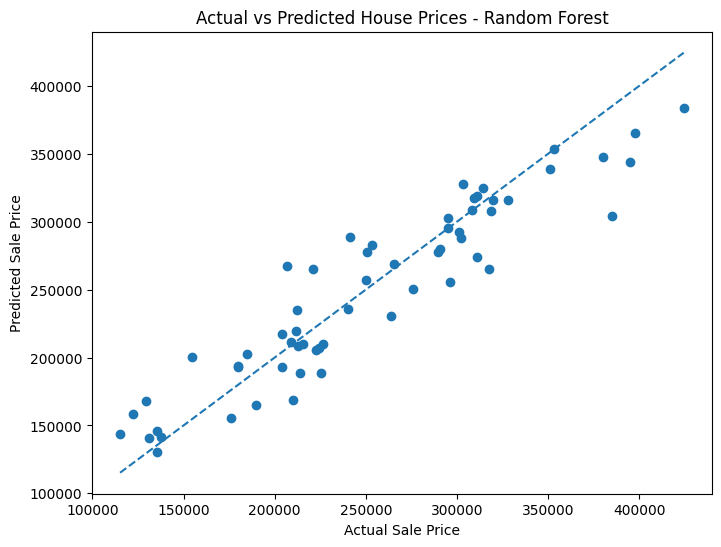

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_rf)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices - Random Forest")

plt.show()

In [ ]:
new_house = pd.DataFrame({
    "OverallQual": [7],
    "GrLivArea": [2000],
    "GarageCars": [2],
    "TotalBsmtSF": [1500],
    "YearBuilt": [2010],
    "FullBath": [2],
    "BedroomAbvGr": [3],
    "LotArea": [8000]
})

predicted_price = lr_model.predict(new_house)

print("Predicted House Price:", predicted_price[0])

Predicted House Price: 292866.9349245613


In [ ]:
import joblib

joblib.dump(lr_model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("house_price_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>